# El error, descompuesto

**Aprendizaje Automático · Doctorado en Ingeniería · Universidad de Talca**
Clase 3, unidad 1 · Genera la figura de la lámina «Con números»

---

La clase afirma que el error esperado de un modelo se parte en tres sumandos
—sesgo al cuadrado, varianza y ruido irreducible— y que al aumentar la capacidad
el primero baja y el segundo sube.

Aquí lo medimos. El experimento es el de la lámina: repetir el estudio muchas
veces con muestras independientes de la misma distribución, algo que en la vida
real no se puede hacer y que en simulación sí.

## El diseño

| | |
|---|---|
| Función verdadera | $f(x)=\operatorname{sen}(2\pi x)$, la misma de la clase 1 |
| Ruido | $\varepsilon\sim N(0,\ 0{,}25^2)$, de modo que $\sigma^2 = 0{,}0625$ |
| Réplicas | 300 muestras independientes de $n=25$ |
| Modelos | polinomios de grado 1 a 12 |
| Punto de evaluación | $x_0 = 0{,}35$ |

La identidad que vamos a comprobar numéricamente es

$$\mathbb{E}\bigl[(y-\hat h_S(x_0))^2\bigr]=
\bigl(f(x_0)-\bar h(x_0)\bigr)^2+
\mathbb{E}\bigl[(\hat h_S(x_0)-\bar h(x_0))^2\bigr]+
\sigma^2$$

Si la suma de los tres términos no reproduce el error total, algo está mal —y la
sección 8 falla ruidosamente.

## 1. Entorno

Se declara para que un tercero pueda reproducir el resultado exacto. Es el ítem 2
de la lista de cotejo de los talleres.

In [1]:
import sys, platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print("Python     ", sys.version.split()[0], "|", platform.system(), platform.machine())
print("numpy      ", np.__version__)
print("matplotlib ", matplotlib.__version__)

Python      3.12.14 | Darwin arm64
numpy       2.2.6
matplotlib  3.10.9


## 2. Parámetros

Todo lo que gobierna el resultado está aquí, con nombre. `N_REPLICAS = 300` es
un compromiso: con menos, la varianza estimada es ruidosa; con muchas más, el
cuaderno tarda sin cambiar la conclusión. La sección 8 verifica que 300 basta.

In [2]:
SEMILLA = 3
N_REPLICAS = 300            # muestras independientes de la misma distribución
N_ENTRENAMIENTO = 25        # tamaño de cada muestra
SIGMA = 0.25                # desviación del ruido; sigma**2 es el piso
GRADOS = range(1, 13)       # capacidad de la familia
X0 = 0.35                   # punto donde se descompone el error

def f_verdadera(x):
    """La función que genera los datos. En un problema real, desconocida."""
    return np.sin(2 * np.pi * x)

print(f"Piso de ruido  sigma^2 = {SIGMA**2:.4f}")
print(f"f(x0) = {f_verdadera(X0):.4f}")

Piso de ruido  sigma^2 = 0.0625
f(x0) = 0.8090


## 3. Protocolo

**Cada réplica es un estudio completo e independiente.** Se genera su propia
muestra, se ajusta un polinomio de cada grado, y se registra la predicción en
$x_0$. Nada se comparte entre réplicas salvo la función verdadera y el nivel de
ruido.

No hay conjunto de prueba aquí porque no hace falta: conocemos $f$, así que el
sesgo se calcula exactamente y no se estima. Esa es la ventaja de la simulación,
y también la razón de que este cuaderno **no** sea un protocolo de evaluación
—los protocolos con datos reales son la unidad 3.

In [3]:
rng = np.random.default_rng(SEMILLA)

# predicciones[r, g] = predicción en x0 del modelo de grado GRADOS[g]
#                      entrenado con la réplica r
predicciones = np.empty((N_REPLICAS, len(GRADOS)))

for r in range(N_REPLICAS):
    x = np.sort(rng.uniform(0, 1, N_ENTRENAMIENTO))
    y = f_verdadera(x) + rng.normal(0, SIGMA, N_ENTRENAMIENTO)
    for g, grado in enumerate(GRADOS):
        coef = np.polyfit(x, y, grado)
        predicciones[r, g] = np.polyval(coef, X0)

print(f"Predicciones registradas: {predicciones.shape[0]} réplicas "
      f"x {predicciones.shape[1]} grados")

Predicciones registradas: 300 réplicas x 12 grados


## 4. Los tres términos

- **Sesgo²** — cuánto se desvía la predicción *promedio sobre réplicas* del valor verdadero.
- **Varianza** — cuánto se dispersan las predicciones alrededor de ese promedio.
- **Ruido** — $\sigma^2$, constante, y por definición fuera de nuestro alcance.

In [4]:
prediccion_media = predicciones.mean(axis=0)          # h barra en x0
sesgo2 = (f_verdadera(X0) - prediccion_media) ** 2
varianza = predicciones.var(axis=0, ddof=0)
ruido = np.full(len(GRADOS), SIGMA ** 2)
total = sesgo2 + varianza + ruido

print(f"{'grado':>6} {'sesgo^2':>12} {'varianza':>12} {'ruido':>10} {'total':>12}")
print("-" * 56)
for i, g in enumerate(GRADOS):
    marca = "  <- mínimo" if i == int(np.argmin(total)) else ""
    print(f"{g:>6} {sesgo2[i]:>12.4f} {varianza[i]:>12.4f} "
          f"{ruido[i]:>10.4f} {total[i]:>12.4f}{marca}")

 grado      sesgo^2     varianza      ruido        total
--------------------------------------------------------
     1       0.2757       0.0149     0.0625       0.3531
     2       0.2554       0.0237     0.0625       0.3416
     3       0.0053       0.0089     0.0625       0.0767
     4       0.0045       0.0092     0.0625       0.0762
     5       0.0000       0.0128     0.0625       0.0753  <- mínimo
     6       0.0000       0.0160     0.0625       0.0785
     7       0.0000       0.0204     0.0625       0.0829
     8       0.0000       0.0278     0.0625       0.0903
     9       0.0001       0.0344     0.0625       0.0970
    10       0.0000       0.0518     0.0625       0.1144
    11       0.0001       0.0704     0.0625       0.1330
    12       0.0002       0.1250     0.0625       0.1877


## 5. Figura

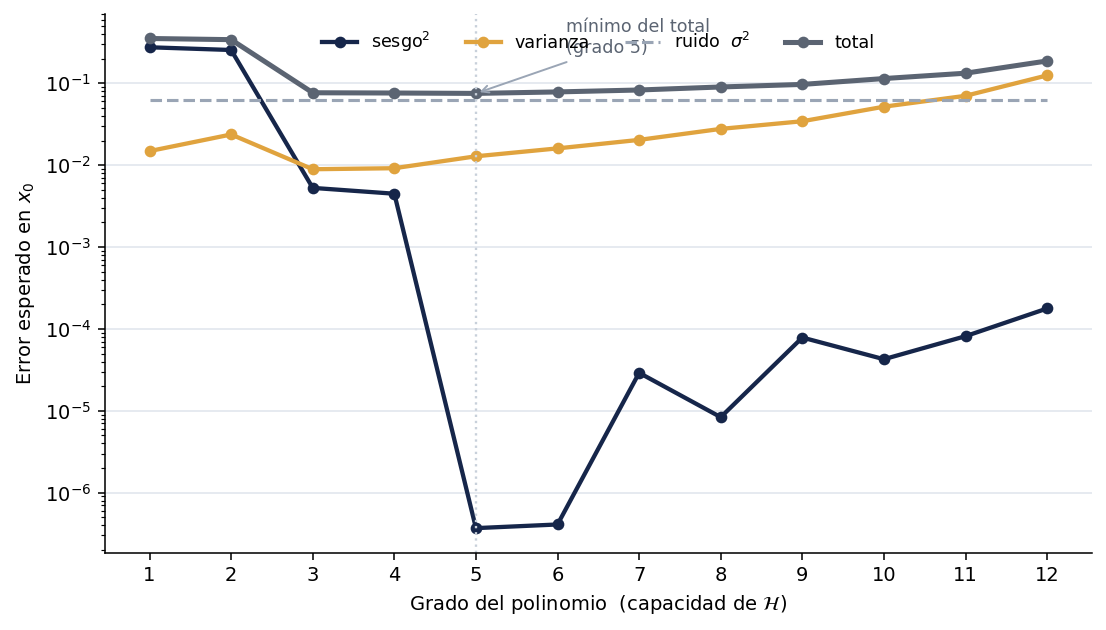

In [5]:
#| label: fig-descomposicion
#| fig-cap: "Sesgo al cuadrado, varianza y ruido en función de la capacidad."
g = list(GRADOS)

fig, ax = plt.subplots(figsize=(8, 4.6), dpi=140)
ax.plot(g, sesgo2, "o-", lw=2.2, ms=5, color="#16264A", label=r"sesgo$^2$")
ax.plot(g, varianza, "o-", lw=2.2, ms=5, color="#E0A33E", label="varianza")
ax.plot(g, ruido, "--", lw=1.6, color="#9AA5B5", label=r"ruido  $\sigma^2$")
ax.plot(g, total, "o-", lw=2.6, ms=5, color="#5B6472", label="total")

mejor = g[int(np.argmin(total))]
ax.axvline(mejor, color="#C8D0DA", ls=":", lw=1.2)
ax.annotate(f"mínimo del total\n(grado {mejor})",
            xy=(mejor, total.min()), xytext=(mejor + 1.1, total.min() + 0.16),
            fontsize=9, color="#5B6472",
            arrowprops=dict(arrowstyle="->", color="#9AA5B5", lw=1))

ax.set_xlabel(r"Grado del polinomio  (capacidad de $\mathcal{H}$)")
ax.set_ylabel(r"Error esperado en $x_0$")
ax.set_xticks(g)
ax.set_yscale("log")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E6EAF0", lw=1)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=4, loc="upper center", fontsize=9)

fig.tight_layout()
fig.savefig("descomposicion_sesgo_varianza.png", dpi=200, bbox_inches="tight")
plt.show()

**Escala logarítmica**, porque la varianza recorre varios órdenes de magnitud
y en escala lineal las tres curvas serían indistinguibles en la mitad izquierda.

Lo que hay que leer:

1. **El sesgo cae y se aplana.** A partir de cierto grado la familia ya puede
   representar la función, y bajar más el sesgo deja de ser posible.
2. **La varianza crece sin freno**, y de forma acelerada.
3. **El total tiene su mínimo antes de que el sesgo se anule.** El mejor modelo
   no es el que mejor *podría* ajustar: es el que mejor equilibra.
4. **El ruido es plano.** Ninguna elección de capacidad lo toca.

## 6. El piso, y por qué conviene conocerlo

El mínimo del total no es cero: no puede serlo, porque $\sigma^2$ está sumando
siempre. Conviene ver qué fracción del error del mejor modelo es irreducible.

In [6]:
i_mejor = int(np.argmin(total))
fraccion = ruido[i_mejor] / total[i_mejor]

print(f"Mejor grado:                {list(GRADOS)[i_mejor]}")
print(f"Error total:                {total[i_mejor]:.4f}")
print(f"De eso, ruido irreducible:  {ruido[i_mejor]:.4f}  ({100*fraccion:.0f} %)")
print(f"Margen de mejora real:      {total[i_mejor] - ruido[i_mejor]:.4f}")

Mejor grado:                5
Error total:                0.0753
De eso, ruido irreducible:  0.0625  (83 %)
Margen de mejora real:      0.0128


Casi todo el error del mejor modelo **es ruido**. Un artículo que persiguiera
mejoras dentro de ese margen estaría persiguiendo algo que no existe.

En un problema real $\sigma^2$ no se conoce, pero muchas veces se puede acotar:
con mediciones repetidas del mismo caso, o con el acuerdo entre anotadores si
las etiquetas son juicios humanos. **Si dos expertos coinciden en el 85 % de los
casos, no espere un clasificador del 95 %.**

## 7. Bitácora

**Decisiones tomadas**

1. *300 réplicas.* La varianza es un estadístico de segundo orden y necesita más
   réplicas que una media para estimarse con estabilidad. La sección 8 comprueba
   que a 300 el resultado ya no se mueve de forma apreciable.
2. *Grados 1 a 12, no hasta 24.* Con $n=25$ un polinomio de grado 24 interpola y
   la varianza se dispara a valores que aplastan la figura sin aportar nada.
3. *Escala logarítmica.* La varianza cubre más de tres órdenes de magnitud entre
   el grado 1 y el 12. En escala lineal las curvas del sesgo y del ruido serían
   dos líneas pegadas al eje.
4. *Descomposición en un punto y no integrada.* En $x_0$ la identidad es exacta y
   se puede verificar término a término. Integrada sobre $x$ también vale, pero
   la verificación exigiría cuadratura y el error de cuadratura se confundiría
   con el error de la identidad.

**Decisión alternativa descartada** — ítem 7 de la lista de cotejo

Se consideró estimar el sesgo comparando contra el promedio de $y$ en vez de
contra $f(x_0)$. **Se descartó** porque el promedio de $y$ incluye el ruido, y
entonces el término de sesgo absorbería parte de $\sigma^2$: la descomposición
seguiría sumando bien pero los tres términos ya no significarían lo que dice la
clase. Aquí se puede usar $f$ porque la conocemos; en un problema real no, y esa
es precisamente la razón de que la descomposición sea una herramienta conceptual
y no un procedimiento.

**Uso de asistentes de IA**

Declarar aquí en qué parte del trabajo se usaron, según la regla operativa del
módulo.

## 8. Verificación

Dos comprobaciones. La primera es la que importa: que la identidad de la clase
se cumpla numéricamente. Se calcula el error total **de forma independiente**
—simulando observaciones nuevas en $x_0$— y se compara con la suma de los tres
términos.

In [7]:
# Error total medido directamente, sin usar la descomposición.
r = np.random.default_rng(SEMILLA + 1000)
y0_nuevos = f_verdadera(X0) + r.normal(0, SIGMA, 200_000)
total_directo = np.array([
    np.mean((y0_nuevos[:, None] - predicciones[:, i][None, :]) ** 2)
    for i in range(len(GRADOS))
])

error_relativo = np.abs(total_directo - total) / total
print(f"{'grado':>6} {'suma de los 3':>15} {'medido directo':>16} {'error rel.':>12}")
print("-" * 52)
for i, gg in enumerate(GRADOS):
    print(f"{gg:>6} {total[i]:>15.4f} {total_directo[i]:>16.4f} {error_relativo[i]:>12.2%}")

assert np.all(error_relativo < 0.02), "La descomposición no reproduce el error total."
print("\nLa identidad sesgo^2 + varianza + ruido = error total se cumple (< 2 %).")

 grado   suma de los 3   medido directo   error rel.
----------------------------------------------------
     1          0.3531           0.3525        0.15%
     2          0.3416           0.3411        0.15%
     3          0.0767           0.0767        0.08%
     4          0.0762           0.0761        0.07%
     5          0.0753           0.0754        0.03%
     6          0.0785           0.0786        0.02%
     7          0.0829           0.0829        0.03%
     8          0.0903           0.0903        0.02%
     9          0.0970           0.0970        0.01%
    10          0.1144           0.1144        0.01%
    11          0.1330           0.1330        0.01%
    12          0.1877           0.1877        0.00%

La identidad sesgo^2 + varianza + ruido = error total se cumple (< 2 %).


In [8]:
# ¿Bastan 300 réplicas? Se recalcula con la mitad y se compara el grado óptimo.
mitad = predicciones[:N_REPLICAS // 2]
total_mitad = ((f_verdadera(X0) - mitad.mean(axis=0)) ** 2
               + mitad.var(axis=0, ddof=0) + SIGMA ** 2)

g_300 = list(GRADOS)[int(np.argmin(total))]
g_150 = list(GRADOS)[int(np.argmin(total_mitad))]
print(f"Grado óptimo con 300 réplicas: {g_300}")
print(f"Grado óptimo con 150 réplicas: {g_150}")
assert g_300 == g_150, "El resultado depende del número de réplicas: use más."
print("La conclusión es estable al reducir a la mitad las réplicas.")

Grado óptimo con 300 réplicas: 5
Grado óptimo con 150 réplicas: 5
La conclusión es estable al reducir a la mitad las réplicas.
